In [24]:
import os
print(os.listdir("../data"))


['eco2mix-national-tr.csv']


In [25]:
import pandas as pd

df = pd.read_csv("../data/eco2mix-national-tr.csv", sep=";")
print(df.shape)
df.head()


(8352, 41)


,Périmètre,Nature,Date,Heure,Date - Heure,Consommation (MW),Prévision J-1 (MW),Prévision J (MW),Fioul (MW),Charbon (MW),...,Gaz - CCG (MW),Gaz - Autres (MW),Hydraulique - Fil de l'eau + éclusée (MW),Hydraulique - Lacs (MW),Hydraulique - STEP turbinage (MW),Bioénergies - Déchets (MW),Bioénergies - Biomasse (MW),Bioénergies - Biogaz (MW),Stockage batterie (MW),Déstockage batterie (MW)
0,France,Données temps réel,2026-09-01,00:00,2026-09-01T00:00:00+02:00,42233.0,41500,41500.0,37.0,0.0,...,2243.0,0.0,2238.0,794.0,654.0,411.0,307.0,301.0,-51.0,1.0
1,France,Données temps réel,2026-09-01,00:15,2026-09-01T00:15:00+02:00,42256.0,40750,40750.0,37.0,0.0,...,2321.0,0.0,2234.0,976.0,778.0,408.0,307.0,301.0,-4.0,38.0
2,France,Données temps réel,2026-09-01,00:30,2026-09-01T00:30:00+02:00,41091.0,40000,40000.0,37.0,0.0,...,1715.0,0.0,2216.0,947.0,157.0,411.0,305.0,301.0,-16.0,0.0
3,France,Données temps réel,2026-09-01,00:45,2026-09-01T00:45:00+02:00,39517.0,39000,39000.0,37.0,0.0,...,1077.0,0.0,2174.0,928.0,157.0,408.0,305.0,301.0,-195.0,0.0
4,France,Données temps réel,2026-09-01,01:00,2026-09-01T01:00:00+02:00,38939.0,38000,38000.0,37.0,0.0,...,912.0,0.0,2184.0,798.0,158.0,412.0,305.0,301.0,-33.0,2.0


In [26]:
print(list(df.columns))

['Périmètre', 'Nature', 'Date', 'Heure', 'Date - Heure', 'Consommation (MW)', 'Prévision J-1 (MW)', 'Prévision J (MW)', 'Fioul (MW)', 'Charbon (MW)', 'Gaz (MW)', 'Nucléaire (MW)', 'Eolien (MW)', 'Eolien terrestre (MW)', 'Eolien offshore (MW)', 'Solaire (MW)', 'Hydraulique (MW)', 'Pompage (MW)', 'Bioénergies (MW)', 'Ech. physiques (MW)', 'Taux de CO2 (g/kWh)', 'Ech. comm. Angleterre (MW)', 'Ech. comm. Espagne (MW)', 'Ech. comm. Italie (MW)', 'Ech. comm. Suisse (MW)', 'Ech. comm. Allemagne-Belgique (MW)', 'Fioul - TAC (MW)', 'Fioul - Cogénération (MW)', 'Fioul - Autres (MW)', 'Gaz - TAC (MW)', 'Gaz - Cogénération (MW)', 'Gaz - CCG (MW)', 'Gaz - Autres (MW)', "Hydraulique - Fil de l'eau + éclusée (MW)", 'Hydraulique - Lacs (MW)', 'Hydraulique - STEP turbinage (MW)', 'Bioénergies - Déchets (MW)', 'Bioénergies - Biomasse (MW)', 'Bioénergies - Biogaz (MW)', 'Stockage batterie (MW)', 'Déstockage batterie (MW)']


In [27]:
df.iloc[:5, :6]

,Périmètre,Nature,Date,Heure,Date - Heure,Consommation (MW)
0,France,Données temps réel,2026-09-01,00:00,2026-09-01T00:00:00+02:00,42233.0
1,France,Données temps réel,2026-09-01,00:15,2026-09-01T00:15:00+02:00,42256.0
2,France,Données temps réel,2026-09-01,00:30,2026-09-01T00:30:00+02:00,41091.0
3,France,Données temps réel,2026-09-01,00:45,2026-09-01T00:45:00+02:00,39517.0
4,France,Données temps réel,2026-09-01,01:00,2026-09-01T01:00:00+02:00,38939.0


In [28]:
df["Date"] = pd.to_datetime(df["Date"])
conso_jour = df.groupby("Date")["Consommation (MW)"].mean().reset_index()
conso_jour.columns = ["date", "conso_moyenne"]
print(conso_jour.shape)
conso_jour.head()


(87, 2)


,date,conso_moyenne
0,2026-09-01,43653.572917
1,2026-09-02,44384.947917
2,2026-09-03,44981.531250
3,2026-09-04,45772.656250
4,2026-09-05,40610.802083


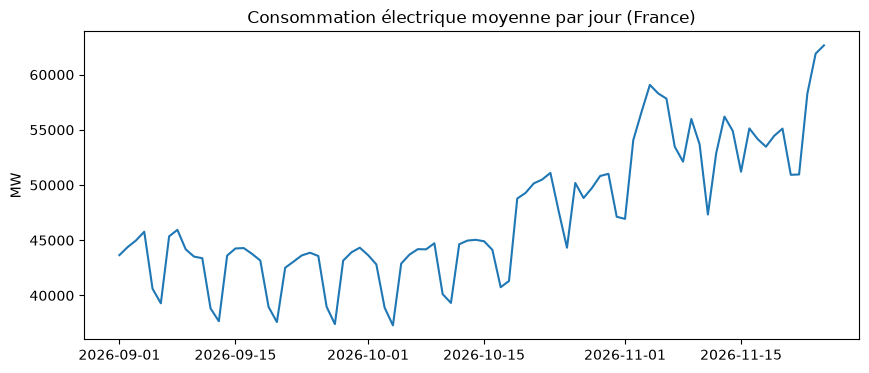

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(conso_jour["date"], conso_jour["conso_moyenne"])
plt.title("Consommation électrique moyenne par jour (France)")
plt.ylabel("MW")
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_3204\1350281708.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  conso_jour["jour_semaine"] = conso_jour["date"].dt.dayofweek


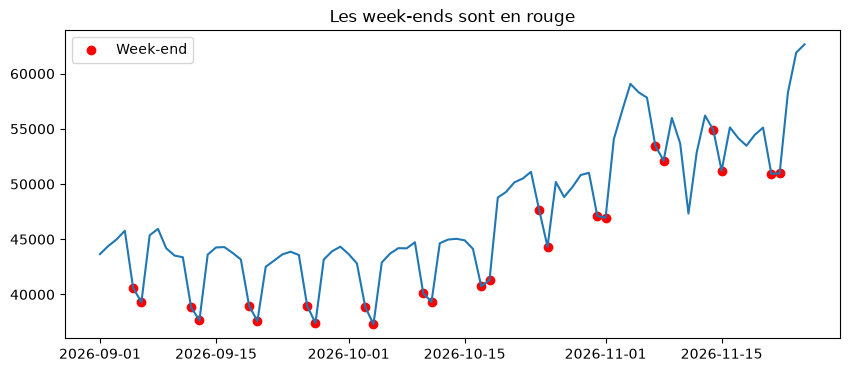

In [30]:
conso_jour["jour_semaine"] = conso_jour["date"].dt.dayofweek
conso_jour["weekend"] = conso_jour["jour_semaine"] >= 5
plt.figure(figsize=(10, 4))
plt.plot(conso_jour["date"], conso_jour["conso_moyenne"])

we = conso_jour[conso_jour["weekend"]]
plt.scatter(we["date"], we["conso_moyenne"], color="red", label="Week-end")

plt.legend()
plt.title("Les week-ends sont en rouge")
plt.show()

In [31]:
conso_jour["jour_semaine"] = conso_jour["date"].dt.dayofweek
conso_jour["conso_hier"] = conso_jour["conso_moyenne"].shift(1)
conso_jour["conso_7j"] = conso_jour["conso_moyenne"].shift(7)
print(conso_jour.shape)
conso_jour.head(10)

(87, 6)


C:\Users\Admin\AppData\Local\Temp\ipykernel_3204\209546559.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  conso_jour["jour_semaine"] = conso_jour["date"].dt.dayofweek


,date,conso_moyenne,jour_semaine,weekend,conso_hier,conso_7j
0,2026-09-01,43653.572917,1,False,NaN,NaN
1,2026-09-02,44384.947917,2,False,43653.572917,NaN
2,2026-09-03,44981.531250,3,False,44384.947917,NaN
3,2026-09-04,45772.656250,4,False,44981.531250,NaN
4,2026-09-05,40610.802083,5,True,45772.656250,NaN
5,2026-09-06,39289.708333,6,True,40610.802083,NaN
6,2026-09-07,45355.906250,0,False,39289.708333,NaN
7,2026-09-08,45940.479167,1,False,45355.906250,43653.572917
8,2026-09-09,44178.041667,2,False,45940.479167,44384.947917
9,2026-09-10,43521.250000,3,False,44178.041667,44981.531250


In [32]:
conso_jour = conso_jour.dropna().reset_index(drop=True)
print(conso_jour.shape)

(79, 6)


In [33]:
conso_jour.groupby("weekend")["conso_moyenne"].mean()

weekend
False    48798.764505
True     43941.097538
Name: conso_moyenne, dtype: float64

In [34]:
coupure = len(conso_jour) - 17

train = conso_jour.iloc[:coupure]
test = conso_jour.iloc[coupure:]

print("Entraînement :", train.shape, train["date"].min(), "->", train["date"].max())
print("Test :", test.shape, test["date"].min(), "->", test["date"].max())

Entraînement : (62, 6) 2026-09-08 00:00:00 -> 2026-11-08 00:00:00
Test : (17, 6) 2026-11-09 00:00:00 -> 2026-11-25 00:00:00


In [35]:
from sklearn.metrics import mean_absolute_error

vrai = test["conso_moyenne"]

mae_hier = mean_absolute_error(vrai, test["conso_hier"])
mae_7j = mean_absolute_error(vrai, test["conso_7j"])

print("Erreur règle 'comme hier' :", round(mae_hier), "MW")
print("Erreur règle 'comme il y a 7 jours' :", round(mae_7j), "MW")

Erreur règle 'comme hier' : 2912 MW
Erreur règle 'comme il y a 7 jours' : 3554 MW


In [36]:
from sklearn.linear_model import LinearRegression

variables = ["conso_hier", "conso_7j", "jour_semaine"]

X_train = train[variables]
y_train = train["conso_moyenne"]
X_test = test[variables]
y_test = test["conso_moyenne"]

modele = LinearRegression()
modele.fit(X_train, y_train)

predictions = modele.predict(X_test)
mae_modele = mean_absolute_error(y_test, predictions)
print("Erreur du modèle :", round(mae_modele), "MW")

Erreur du modèle : 2195 MW


In [37]:
for nom, coef in zip(variables, modele.coef_):
    print(nom, round(coef, 3))
print("constante :", round(modele.intercept_))

conso_hier 0.692
conso_7j 0.418
jour_semaine -662.08
constante : -2315


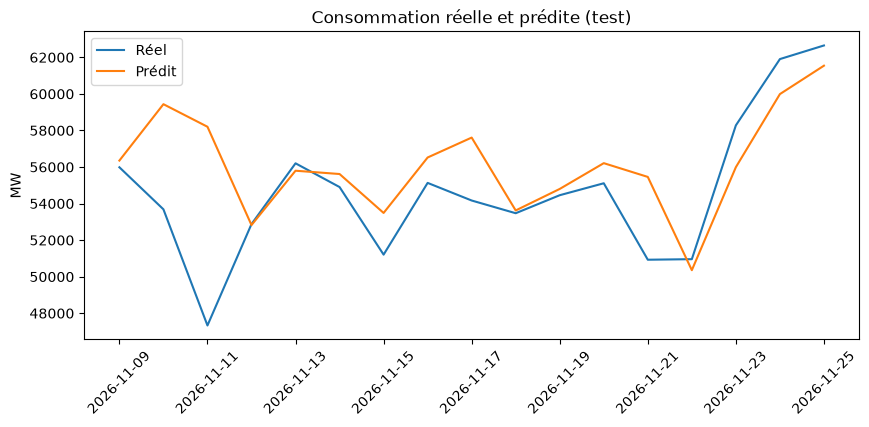

In [38]:
plt.figure(figsize=(10, 4))
plt.plot(test["date"], y_test, label="Réel")
plt.plot(test["date"], predictions, label="Prédit")
plt.legend()
plt.title("Consommation réelle et prédite (test)")
plt.ylabel("MW")
plt.xticks(rotation=45)
plt.show()

In [39]:
train = train.copy()
test = test.copy()
train["weekend"] = train["weekend"].astype(int)
test["weekend"] = test["weekend"].astype(int)

variables2 = ["conso_hier", "conso_7j", "jour_semaine", "weekend"]

modele2 = LinearRegression()
modele2.fit(train[variables2], train["conso_moyenne"])
pred2 = modele2.predict(test[variables2])

print("Erreur avec weekend :", round(mean_absolute_error(test["conso_moyenne"], pred2)), "MW")

Erreur avec weekend : 2277 MW


In [40]:
erreurs = test[["date"]].copy()
erreurs["reel"] = y_test.values
erreurs["predit"] = predictions
erreurs["ecart"] = (erreurs["predit"] - erreurs["reel"]).round()
erreurs

,date,reel,predit,ecart
62,2026-11-09,55984.447917,56351.504893,367.0
63,2026-11-10,53684.010417,59435.545852,5752.0
64,2026-11-11,47330.833333,58201.109762,10870.0
65,2026-11-12,52876.812500,52823.258185,-54.0
66,2026-11-13,56201.135417,55796.287730,-405.0
67,2026-11-14,54902.947917,55615.915658,713.0
68,2026-11-15,51206.010417,53486.586318,2281.0
69,2026-11-16,55130.302083,56519.873438,1390.0
70,2026-11-17,54166.802083,57609.259580,3442.0
71,2026-11-18,53471.250000,53622.871738,152.0


In [41]:
erreurs["ecart_abs"] = erreurs["ecart"].abs()

print("Erreur moyenne (tous les jours) :", round(erreurs["ecart_abs"].mean()), "MW")

sans_ferie = erreurs[erreurs["date"] != "2026-11-11"]
print("Erreur moyenne sans le 11 novembre :", round(sans_ferie["ecart_abs"].mean()), "MW")

Erreur moyenne (tous les jours) : 2195 MW
Erreur moyenne sans le 11 novembre : 1652 MW


In [42]:
from lightgbm import LGBMRegressor

modele_lgbm = LGBMRegressor(n_estimators=200, learning_rate=0.05,
                            min_child_samples=5, random_state=42, verbose=-1)
modele_lgbm.fit(train[variables], train["conso_moyenne"])

pred_lgbm = modele_lgbm.predict(test[variables])
print("Erreur LightGBM :", round(mean_absolute_error(test["conso_moyenne"], pred_lgbm)), "MW")

Erreur LightGBM : 3563 MW


In [43]:
comparaison = test[["date"]].copy()
comparaison["reel"] = y_test.values
comparaison["lgbm"] = pred_lgbm.round()
comparaison.tail(5)

,date,reel,lgbm
74,2026-11-21,50927.447917,57352.0
75,2026-11-22,50957.645833,51947.0
76,2026-11-23,58278.072917,53689.0
77,2026-11-24,61903.291667,57436.0
78,2026-11-25,62647.691358,58623.0


In [44]:
comparaison = test[["date"]].copy()
comparaison["reel"] = y_test.values
comparaison["lgbm"] = pred_lgbm.round()
comparaison.tail(5)

,date,reel,lgbm
74,2026-11-21,50927.447917,57352.0
75,2026-11-22,50957.645833,51947.0
76,2026-11-23,58278.072917,53689.0
77,2026-11-24,61903.291667,57436.0
78,2026-11-25,62647.691358,58623.0


In [45]:
def prevoir_7_jours(modele, historique, variables):
    valeurs = list(historique["conso_moyenne"])
    derniere_date = historique["date"].iloc[-1]
    resultats = []

    for i in range(1, 8):
        date = derniere_date + pd.Timedelta(days=i)
        conso_hier = valeurs[-1]
        conso_7j = valeurs[-7]
        ligne = pd.DataFrame([{
            "conso_hier": conso_hier,
            "conso_7j": conso_7j,
            "jour_semaine": date.dayofweek,
        }])
        pred = modele.predict(ligne[variables])[0]
        valeurs.append(pred)
        resultats.append({"date": date, "prevision": pred})

    return pd.DataFrame(resultats)

In [46]:
historique = train.copy()
prev = prevoir_7_jours(modele, historique, variables)

reel = test.iloc[:7][["date", "conso_moyenne"]].reset_index(drop=True)
prev["reel"] = reel["conso_moyenne"]
prev["ecart"] = (prev["prevision"] - prev["reel"]).round()
prev

C:\Users\Admin\AppData\Local\Temp\ipykernel_3204\1459239773.py:13: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "jour_semaine": date.dayofweek,
C:\Users\Admin\AppData\Local\Temp\ipykernel_3204\1459239773.py:13: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "jour_semaine": date.dayofweek,
C:\Users\Admin\AppData\Local\Temp\ipykernel_3204\1459239773.py:13: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "jour_semaine": date.dayofweek,
C:\Users\Admin\AppData\Local\Temp\ipykernel_3204\1459239773.py:13: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "jour_semaine": date.dayofweek,
C:\Users\Admin\AppData\Local\Temp\ipykernel_3204\1459239773.py:13: Pandas4Warning: Timestamp

,date,prevision,reel,ecart
0,2026-11-09,56351.504893,55984.447917,367.0
1,2026-11-10,59689.389588,53684.010417,6005.0
2,2026-11-11,62354.219455,47330.833333,15023.0
3,2026-11-12,63212.905323,52876.812500,10336.0
4,2026-11-13,62944.367155,56201.135417,6743.0
5,2026-11-14,60279.298317,54902.947917,5376.0
6,2026-11-15,57204.681767,51206.010417,5999.0


In [47]:
prev["ecart_abs"] = prev["ecart"].abs()
print("Erreur moyenne sur 7 jours :", round(prev["ecart_abs"].mean()), "MW")

Erreur moyenne sur 7 jours : 7121 MW


In [48]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump(modele, "../models/modele_lineaire.joblib")
conso_jour.to_csv("../models/conso_jour.csv", index=False)

In [49]:
print(os.listdir("../models"))


['conso_jour.csv', 'modele_lineaire.joblib']


In [50]:
import sys
sys.path.append("../src")

import donnees
tableau = donnees.preparer("../data/eco2mix-national-tr.csv")
print(tableau.shape)
tableau.head()

(79, 5)


,date,conso_moyenne,jour_semaine,conso_hier,conso_7j
0,2026-09-08,45940.479167,1,45355.906250,43653.572917
1,2026-09-09,44178.041667,2,45940.479167,44384.947917
2,2026-09-10,43521.250000,3,44178.041667,44981.531250
3,2026-09-11,43372.343750,4,43521.250000,45772.656250
4,2026-09-12,38823.843750,5,43372.343750,40610.802083
